# Freight Rate Prediction: Exploratory Analysis, Data Quality and Model Evaluation

This notebook documents the analysis behind `src/pipeline.py`:

1. **Populations and timeline**: what each dataset covers and how the data is split
2. **Target analysis**: rate and rate-per-mile distributions
3. **Data quality**: every issue found and how it is handled
4. **Population shift**: how the validation set differs from the training data
5. **Rate drivers**: what moves the price
6. **Validation strategy**: why a time-based split, and what a random split would hide
7. **Model results**: baselines vs LightGBM, errors by segment, feature importance
8. **Final prediction checks**: sanity checks on the 12,000 validation predictions
9. **December chart**: fixed-input predictions compared with lane history

The cleaning, feature and metric functions are imported from `src/pipeline.py`, so this
notebook analyses exactly the logic used for the submission. All charts are saved to
`outputs/figures/`.

In [21]:
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message=".*eval_set.*")

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, "src")

import lightgbm as lgb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
import numpy as np
import pandas as pd

from pipeline import (
    EQUIPMENT, FEATURES, HOLDOUT_START, PARAMS,
    add_features, build_december, clean, learn_reference, metrics, straight_line,
)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

FIG_DIR = Path("outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E3E8EA", "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left",
})
POP = {"Train (Jan-Aug)": "#064A56", "Holdout (Sep-Oct)": "#E07A1F", "Validation (Nov-Dec)": "#7A9E3B"}
EQ_COLORS = {"Dry Van": "#064A56", "Reefer": "#3A8FB7", "Flatbed": "#E07A1F"}
BAD = "#C0392B"


DOLLARS = FuncFormatter(lambda v, _: f"${v:,.0f}")


def dollar_log_axis(axis):
    axis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    axis.set_major_formatter(DOLLARS)
    axis.set_minor_formatter(NullFormatter())


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 0. Load the data

In [22]:
raw_train = pd.read_csv("data/train-test.csv", parse_dates=["date"])
raw_valid = pd.read_csv("data/validation.csv", parse_dates=["date"])
raw_dec = pd.read_csv("data/december-chart-inputs.csv")


def describe_population(df, name):
    cities = set(df["pickup"]) | set(df["delivery"])
    return {
        "dataset": name, "rows": len(df), "columns": df.shape[1],
        "first date": df["date"].min().date(), "last date": df["date"].max().date(),
        "days": df["date"].nunique(), "cities": len(cities),
        "lanes": df.groupby(["pickup", "delivery"]).ngroups,
        "loads per day": round(len(df) / df["date"].nunique(), 1),
    }


pd.DataFrame([describe_population(raw_train, "train-test.csv"),
              describe_population(raw_valid, "validation.csv")]).set_index("dataset")

,rows,columns,first date,last date,days,cities,lanes,loads per day
dataset,,,,,,,,
train-test.csv,48000,14,2025-01-01,2025-10-31,304,64,4014,157.9
validation.csv,12000,13,2025-11-01,2025-12-31,61,72,4214,196.7


## 1. Populations and timeline

The labelled data ends on 31 October and the validation loads run from 1 November to
31 December. The task is therefore **forecasting**: every prediction is for a date the
model has never seen. The development data is split by time so that model evaluation
mirrors this situation.

[clean train-test] negative weights fixed: 292 | missing weight filled: 300 | missing market_index filled: 374 | short trips with high distance ratio (kept): 214
[clean validation] negative weights fixed: 145 | missing weight filled: 165 | missing market_index filled: 249 | short trips with high distance ratio (kept): 55


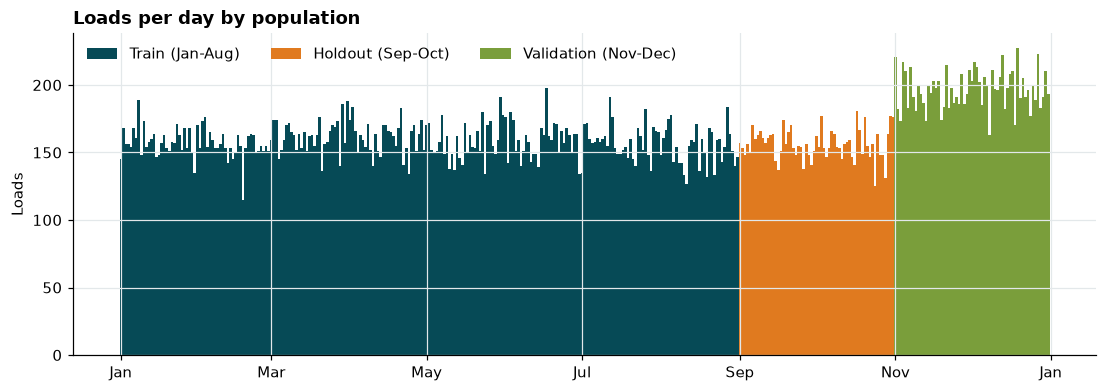

,loads
population,
Train (Jan-Aug),38477
Holdout (Sep-Oct),9523
Validation (Nov-Dec),12000


In [23]:
ref = learn_reference(raw_train)
train_clean = clean(raw_train, ref, "train-test")
valid_clean = clean(raw_valid, ref, "validation")


def population(date):
    if date >= pd.Timestamp("2025-11-01"):
        return "Validation (Nov-Dec)"
    return "Holdout (Sep-Oct)" if date >= HOLDOUT_START else "Train (Jan-Aug)"


timeline = pd.concat([raw_train[["date"]], raw_valid[["date"]]])
timeline["population"] = timeline["date"].map(population)
weekly = timeline.groupby(["date", "population"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(12, 3.8))
bottom = np.zeros(len(weekly))
for name, color in POP.items():
    if name in weekly:
        ax.bar(weekly.index, weekly[name], width=1, bottom=bottom, color=color, label=name)
        bottom += weekly[name].values
ax.set_title("Loads per day by population")
ax.set_ylabel("Loads")
ax.legend(loc="upper left", ncol=3, frameon=False)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
save(fig, "01_population_timeline")
plt.show()

timeline["population"].value_counts().reindex(POP).to_frame("loads")

## 2. Target analysis: rate and rate per mile

The raw rate mostly reflects trip length, so rate per mile (RPM) is the better lens for
spotting errors. A load is flagged as an implausible rate when its RPM is below 0.5x or
above 2x the median RPM of loads with similar distance and the same equipment. This is
the same rule used in `pipeline.py`.

Implausible rates: 677 rows (1.41%)
  too low  (<0.5x typical): 337
  too high (>2x typical):   340


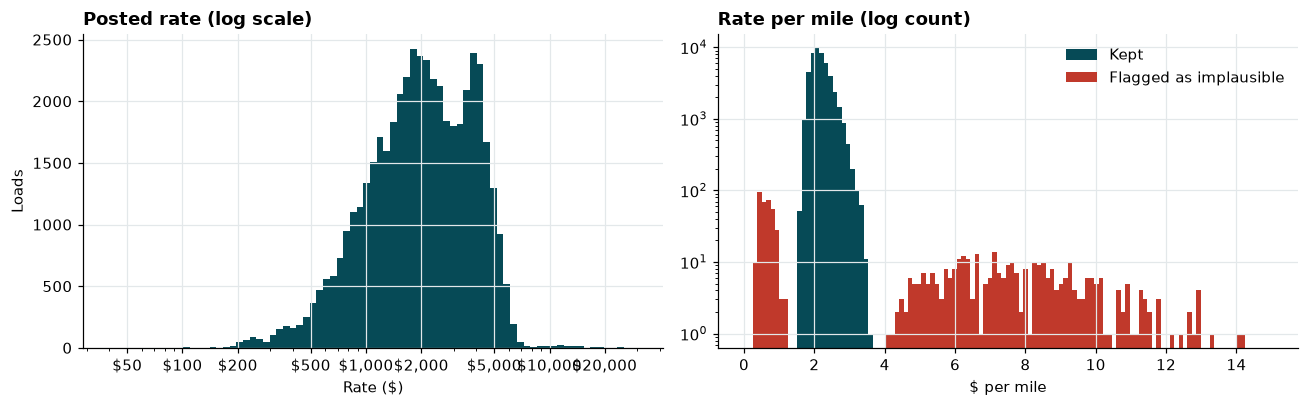

In [24]:
def rate_outlier_flags(df):
    rpm = df["posted_rate"] / df["distance"]
    bucket = pd.qcut(df["distance"], 10, labels=False, duplicates="drop")
    typical = rpm.groupby([bucket, df["equipment"]]).transform("median")
    ratio = rpm / typical
    return rpm, ratio, (ratio < 0.5) | (ratio > 2.0)


train_clean["rpm"], train_clean["rpm_ratio"], train_clean["rate_outlier"] = rate_outlier_flags(train_clean)
n_out = int(train_clean["rate_outlier"].sum())
print(f"Implausible rates: {n_out:,} rows ({n_out / len(train_clean):.2%})")
print(f"  too low  (<0.5x typical): {int((train_clean['rpm_ratio'] < 0.5).sum()):,}")
print(f"  too high (>2x typical):   {int((train_clean['rpm_ratio'] > 2.0).sum()):,}")

ok = train_clean[~train_clean["rate_outlier"]]
bad = train_clean[train_clean["rate_outlier"]]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(train_clean["posted_rate"], bins=np.logspace(np.log10(40), np.log10(30000), 80), color="#064A56")
axes[0].set_xscale("log")
dollar_log_axis(axes[0].xaxis)
axes[0].set_title("Posted rate (log scale)")
axes[0].set_xlabel("Rate ($)")
axes[0].set_ylabel("Loads")

bins = np.linspace(0, 15, 120)
axes[1].hist(ok["rpm"], bins=bins, color="#064A56", label="Kept")
axes[1].hist(bad["rpm"], bins=bins, color=BAD, label="Flagged as implausible")
axes[1].set_yscale("log")
axes[1].set_title("Rate per mile (log count)")
axes[1].set_xlabel("$ per mile")
axes[1].legend(frameon=False)
fig.tight_layout()
save(fig, "02_target_distribution")
plt.show()

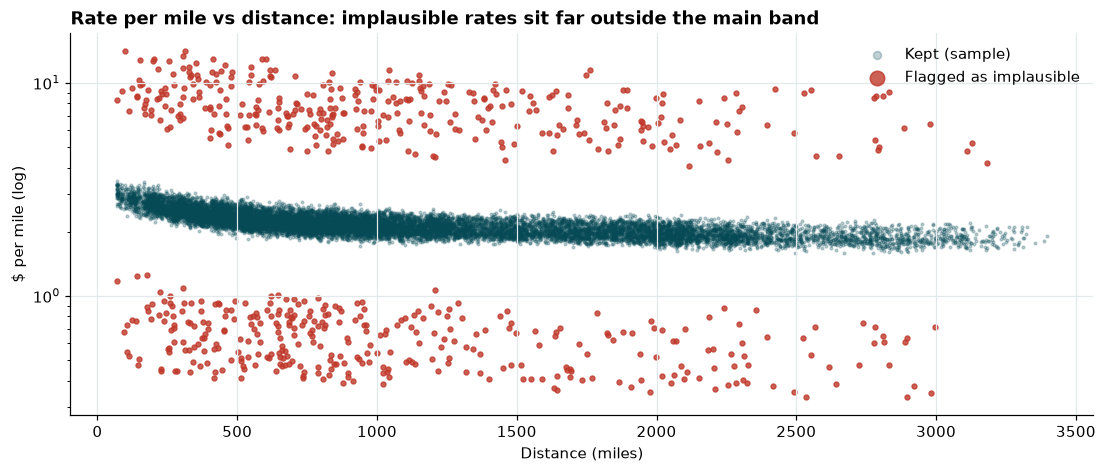

,load_id,pickup,delivery,distance,equipment,date,posted_rate,rpm,rpm_ratio
45059,TR-045060,Raleigh,Columbia,420.9,Reefer,2025-10-13,183.77,0.44,0.17
2511,TR-002512,Buffalo,San Antonio,1644.3,Flatbed,2025-01-16,596.04,0.36,0.17
508,TR-000509,Las Vegas,Grand Rapids,1976.4,Flatbed,2025-01-04,699.41,0.35,0.17
10599,TR-010600,Greensboro,Charleston,284.9,Dry Van,2025-03-09,126.54,0.44,0.18
18954,TR-018955,Cincinnati,St. Louis,228.7,Dry Van,2025-04-29,101.63,0.44,0.18
46399,TR-046400,Indianapolis,Madison,276.6,Dry Van,2025-10-21,123.32,0.45,0.18
4674,TR-004675,Hartford,Baltimore,149.3,Reefer,2025-01-30,75.19,0.50,0.18
11236,TR-011237,Columbia,Lexington,228.3,Dry Van,2025-03-13,103.15,0.45,0.18
33585,TR-033586,Fresno,Los Angeles,416.2,Dry Van,2025-07-31,171.28,0.41,0.18
17602,TR-017603,Fort Wayne,Philadelphia,807.7,Flatbed,2025-04-21,328.89,0.41,0.18


In [25]:
fig, ax = plt.subplots(figsize=(12, 4.5))
sample = ok.sample(min(len(ok), 15000), random_state=0)
ax.scatter(sample["distance"], sample["rpm"], s=3, alpha=0.25, color="#064A56", label="Kept (sample)")
ax.scatter(bad["distance"], bad["rpm"], s=10, alpha=0.8, color=BAD, label="Flagged as implausible")
ax.set_yscale("log")
ax.set_title("Rate per mile vs distance: implausible rates sit far outside the main band")
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("$ per mile (log)")
ax.legend(frameon=False, markerscale=3)
save(fig, "03_rpm_vs_distance_outliers")
plt.show()

bad[["load_id", "pickup", "delivery", "distance", "equipment", "date", "posted_rate", "rpm", "rpm_ratio"]] \
    .sort_values("rpm_ratio").head(10).round({"distance": 1, "posted_rate": 2, "rpm": 2, "rpm_ratio": 2})

## 3. Data quality

Every issue below is handled with a rule learned from the training data only, and the
same rule is applied to the validation set. One apparent issue turned out not to be an
error: some recorded distances are far above the straight-line distance, but they are all
short trips, where road routing adds proportionally more miles and recorded distances
bottom out at a 70-mile minimum. Those distances are kept as recorded. Implausible rates are removed from **training
only**; validation rows are never dropped, because every load needs a prediction.

In [26]:
def straight_ratio(df):
    return df["distance"] / straight_line(df)


def quality_table(df, name, has_target):
    ratio = straight_ratio(df)
    rows = {
        "Negative weight (sign error)": int((df["weight"] < 0).sum()),
        "Missing weight": int(df["weight"].isna().sum()),
        "Missing market_index": int(df["market_index"].isna().sum()),
        "Distance >1.5x straight line (short trips)": int(((ratio > 1.5) | (ratio < 1.0)).sum()),
        "Duplicate rows (ignoring load_id)": int(df.drop(columns="load_id").duplicated().sum()),
        "Pickup equals delivery": int((df["pickup"] == df["delivery"]).sum()),
    }
    if has_target:
        rows["Implausible rate per mile"] = n_out
    return pd.Series(rows, name=name)


fixes = pd.Series({
    "Negative weight (sign error)": "Absolute value",
    "Missing weight": "Training median + missing flag",
    "Missing market_index": "Same-day median + missing flag",
    "Distance >1.5x straight line (short trips)": "Kept: genuine short-haul routing, not an error",
    "Duplicate rows (ignoring load_id)": "None found",
    "Pickup equals delivery": "None found",
    "Implausible rate per mile": "Removed from training only",
}, name="Fix")

quality = pd.concat([quality_table(raw_train, "train-test", True),
                     quality_table(raw_valid, "validation", False)], axis=1)
quality["train %"] = (quality["train-test"] / len(raw_train) * 100).round(2)
quality.join(fixes)

,train-test,validation,train %,Fix
Negative weight (sign error),292,145.0,0.61,Absolute value
Missing weight,300,165.0,0.62,Training median + missing flag
Missing market_index,374,249.0,0.78,Same-day median + missing flag
Distance >1.5x straight line (short trips),214,55.0,0.45,"Kept: genuine short-haul routing, not an error"
Duplicate rows (ignoring load_id),0,0.0,0.00,None found
Pickup equals delivery,0,0.0,0.00,None found
Implausible rate per mile,677,NaN,1.41,Removed from training only


Loads with ratio above 1.5: 214 | straight-line distance of those loads: median 52 mi, max 148 mi | recorded distance min 70 mi


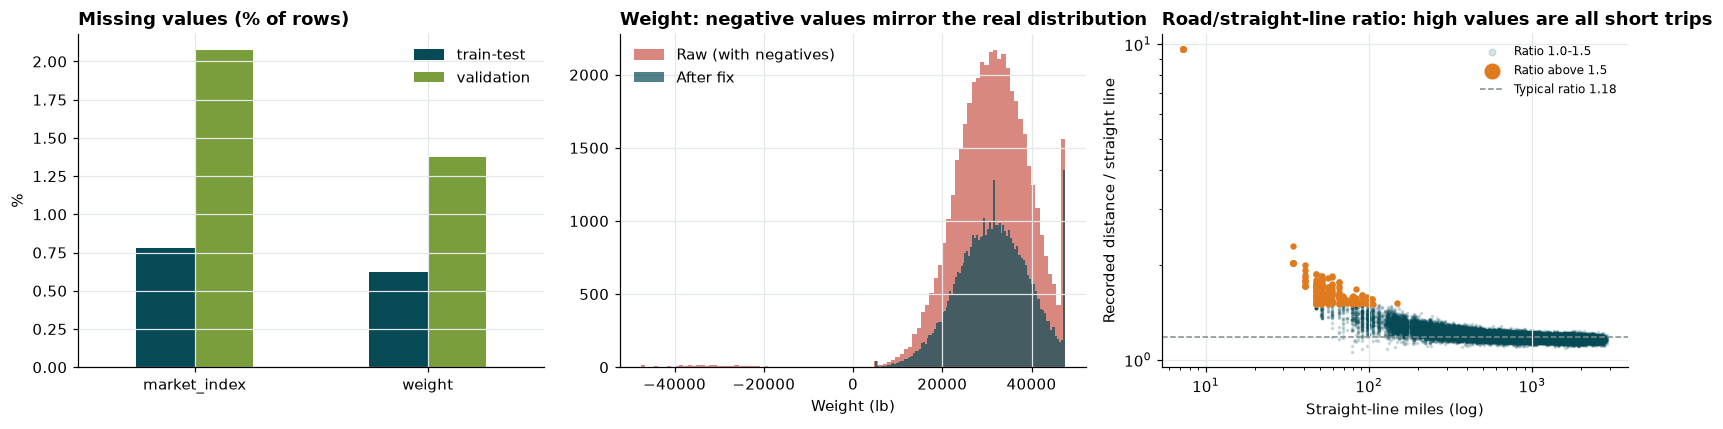

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

missing = pd.DataFrame({
    "train-test": raw_train.isna().mean() * 100,
    "validation": raw_valid.isna().mean() * 100,
}).loc[lambda d: d.max(axis=1) > 0]
missing.plot.bar(ax=axes[0], color=["#064A56", "#7A9E3B"], rot=0)
axes[0].set_title("Missing values (% of rows)")
axes[0].set_ylabel("%")
axes[0].legend(frameon=False)

axes[1].hist(raw_train["weight"].dropna(), bins=100, color=BAD, alpha=0.6, label="Raw (with negatives)")
axes[1].hist(train_clean["weight"], bins=100, color="#064A56", alpha=0.7, label="After fix")
axes[1].set_title("Weight: negative values mirror the real distribution")
axes[1].set_xlabel("Weight (lb)")
axes[1].legend(frameon=False)

straight = straight_line(raw_train)
ratio = raw_train["distance"] / straight
high = (ratio > 1.5) | (ratio < 1.0)
axes[2].scatter(straight[~high], ratio[~high], s=2, alpha=0.15, color="#064A56", label="Ratio 1.0-1.5")
axes[2].scatter(straight[high], ratio[high], s=10, color="#E07A1F", label="Ratio above 1.5")
axes[2].axhline(ref["detour"], color="#7F8C8D", ls="--", lw=1, label=f"Typical ratio {ref['detour']:.2f}")
axes[2].set_xscale("log")
axes[2].set_yscale("log")
axes[2].set_title("Road/straight-line ratio: high values are all short trips")
axes[2].set_xlabel("Straight-line miles (log)")
axes[2].set_ylabel("Recorded distance / straight line")
axes[2].legend(frameon=False, markerscale=3, fontsize=8)
print(f"Loads with ratio above 1.5: {int(high.sum())} | straight-line distance of those loads: "
      f"median {straight[high].median():.0f} mi, max {straight[high].max():.0f} mi | "
      f"recorded distance min {raw_train['distance'].min():.0f} mi")

fig.tight_layout()
save(fig, "04_data_quality")
plt.show()

## 4. Population shift: training vs validation

The model is trained on one population and applied to another. These checks show where
the two differ. The Population Stability Index (PSI) summarises each shift:
below 0.1 is stable, 0.1 to 0.25 is a moderate shift, and above 0.25 is a large shift.

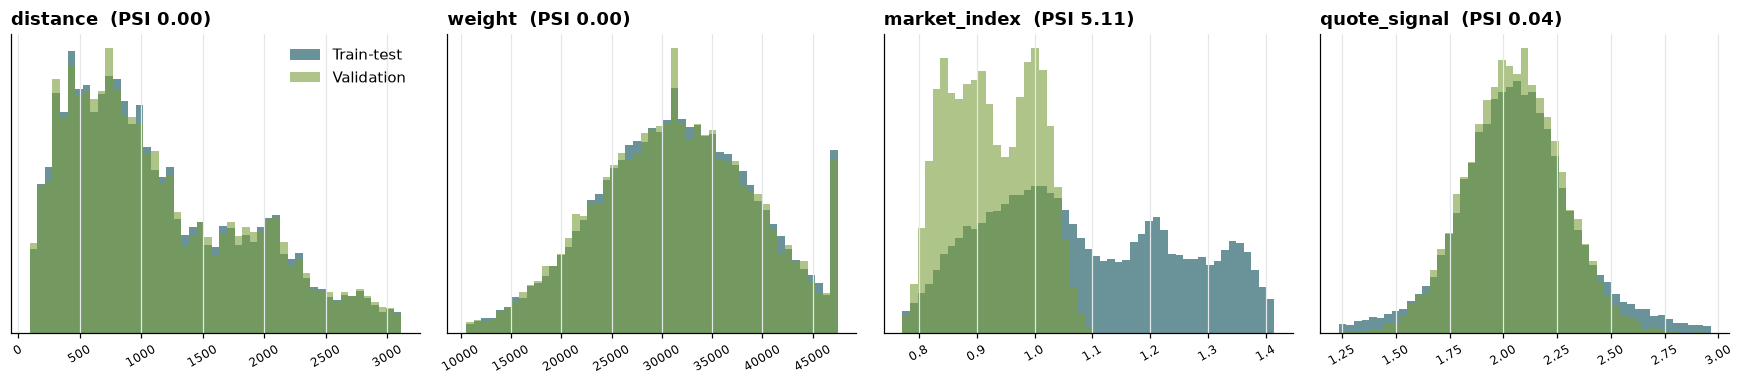

,train mean,validation mean,PSI,shift
distance,1135.857,1141.773,0.001,stable
weight,31417.741,31285.884,0.001,stable
market_index,1.083,0.927,5.108,large
quote_signal,2.062,2.051,0.041,stable


In [28]:
def psi(expected, actual, bins=10):
    expected, actual = pd.Series(expected).dropna(), pd.Series(actual).dropna()
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(actual, edges)[0] / len(actual)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))


shift_cols = ["distance", "weight", "market_index", "quote_signal"]
shift = pd.DataFrame({
    c: {"train mean": train_clean[c].mean(), "validation mean": valid_clean[c].mean(),
        "PSI": psi(train_clean[c], valid_clean[c])}
    for c in shift_cols
}).T.round(3)
shift["shift"] = pd.cut(shift["PSI"], [-1, 0.1, 0.25, np.inf], labels=["stable", "moderate", "large"])

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, c in zip(axes, shift_cols):
    lo, hi = np.nanpercentile(pd.concat([train_clean[c], valid_clean[c]]), [0.5, 99.5])
    b = np.linspace(lo, hi, 50)
    ax.hist(train_clean[c], bins=b, density=True, alpha=0.6, color="#064A56", label="Train-test")
    ax.hist(valid_clean[c], bins=b, density=True, alpha=0.6, color="#7A9E3B", label="Validation")
    ax.set_title(f"{c}  (PSI {shift.loc[c, 'PSI']:.2f})")
    ax.set_yticks([])
    ax.tick_params(axis="x", labelsize=8, rotation=30)
axes[0].legend(frameon=False)
fig.tight_layout()
save(fig, "05_population_shift")
plt.show()
shift

Cities in validation not seen in training: 8 -> ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
Validation loads touching an unseen city: 1,447 (12.1%)
Validation loads on a lane never seen in training: 1,461 (12.2%)
-> City names cannot be used as features; coordinates and distance generalise to any city.


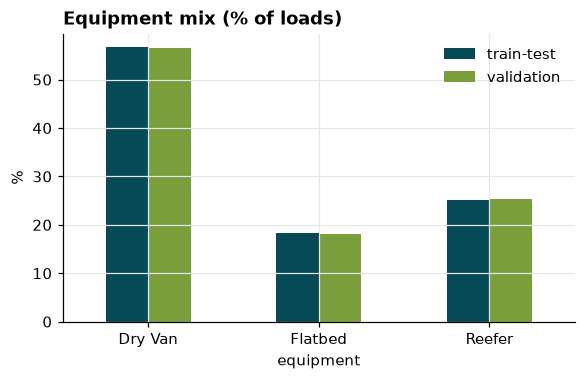

,train-test,validation
equipment,,
Dry Van,56.7,56.5
Flatbed,18.2,18.1
Reefer,25.1,25.4


In [29]:
train_cities = set(raw_train["pickup"]) | set(raw_train["delivery"])
valid_cities = set(raw_valid["pickup"]) | set(raw_valid["delivery"])
new_cities = sorted(valid_cities - train_cities)
unseen_rows = raw_valid["pickup"].isin(new_cities) | raw_valid["delivery"].isin(new_cities)
train_lanes = set(zip(raw_train["pickup"], raw_train["delivery"]))
unseen_lane = ~pd.Series(list(zip(raw_valid["pickup"], raw_valid["delivery"]))).isin(train_lanes)

print(f"Cities in validation not seen in training: {len(new_cities)} -> {new_cities}")
print(f"Validation loads touching an unseen city: {int(unseen_rows.sum()):,} ({unseen_rows.mean():.1%})")
print(f"Validation loads on a lane never seen in training: {int(unseen_lane.sum()):,} ({unseen_lane.mean():.1%})")
print("-> City names cannot be used as features; coordinates and distance generalise to any city.")

mix = pd.DataFrame({
    "train-test": raw_train["equipment"].value_counts(normalize=True),
    "validation": raw_valid["equipment"].value_counts(normalize=True),
}).reindex(EQUIPMENT) * 100

fig, ax = plt.subplots(figsize=(6, 3.4))
mix.plot.bar(ax=ax, color=["#064A56", "#7A9E3B"], rot=0)
ax.set_title("Equipment mix (% of loads)")
ax.set_ylabel("%")
ax.legend(frameon=False)
save(fig, "06_equipment_mix")
plt.show()
mix.round(1)

## 5. What drives the rate

Distance sets the scale of the price; equipment, market conditions and lane adjust it.
Rate per mile falls with distance because fixed costs (loading, waiting time) are
spread over more miles.

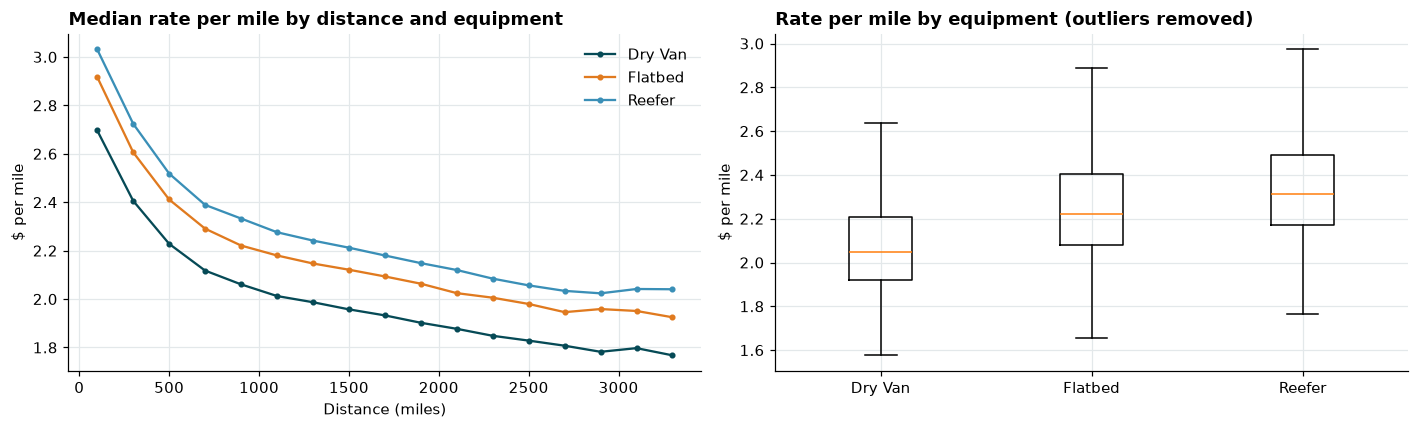

,count,25%,50%,75%
equipment,,,,
Dry Van,26834.0,1.922,2.046,2.208
Flatbed,8626.0,2.078,2.220,2.403
Reefer,11863.0,2.171,2.312,2.492


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for eq in EQUIPMENT:
    d = ok[ok["equipment"] == eq]
    b = pd.cut(d["distance"], np.arange(0, 3600, 200))
    curve = d.groupby(b, observed=True)["rpm"].median()
    axes[0].plot([i.mid for i in curve.index], curve.values, marker="o", ms=3, color=EQ_COLORS[eq], label=eq)
axes[0].set_title("Median rate per mile by distance and equipment")
axes[0].set_xlabel("Distance (miles)")
axes[0].set_ylabel("$ per mile")
axes[0].legend(frameon=False)

axes[1].boxplot([ok.loc[ok["equipment"] == eq, "rpm"] for eq in EQUIPMENT], showfliers=False)
axes[1].set_xticks(range(1, len(EQUIPMENT) + 1), EQUIPMENT)
axes[1].set_title("Rate per mile by equipment (outliers removed)")
axes[1].set_ylabel("$ per mile")
fig.tight_layout()
save(fig, "07_rate_drivers_distance_equipment")
plt.show()

ok.groupby("equipment", observed=True)["rpm"].describe()[["count", "25%", "50%", "75%"]].round(3)

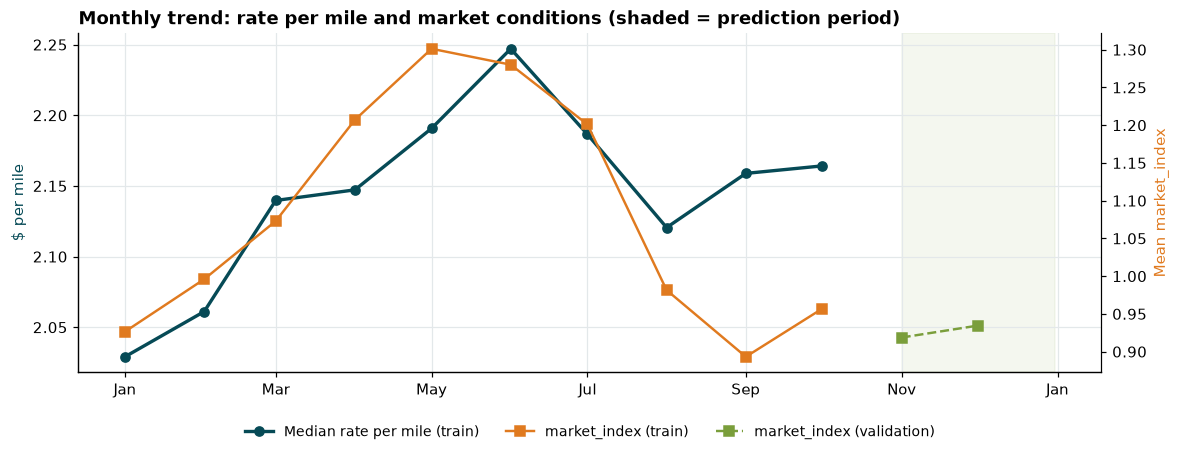

,median_rpm,market_index,quote_signal
date,,,
2025-01,2.029,0.926,2.068
2025-02,2.061,0.996,2.096
2025-03,2.140,1.073,2.179
2025-04,2.147,1.207,1.965
2025-05,2.191,1.301,1.913
2025-06,2.247,1.280,2.297
2025-07,2.187,1.201,1.923
2025-08,2.121,0.981,2.053
2025-09,2.159,0.893,2.200


In [31]:
monthly_train = ok.groupby(ok["date"].dt.to_period("M")).agg(
    median_rpm=("rpm", "median"), market_index=("market_index", "mean"), quote_signal=("quote_signal", "mean"))
monthly_valid = valid_clean.groupby(valid_clean["date"].dt.to_period("M")).agg(
    market_index=("market_index", "mean"), quote_signal=("quote_signal", "mean"))

fig, ax1 = plt.subplots(figsize=(12, 4))
x_train = monthly_train.index.to_timestamp()
x_valid = monthly_valid.index.to_timestamp()
ax1.plot(x_train, monthly_train["median_rpm"], marker="o", color="#064A56", lw=2.2, label="Median rate per mile (train)")
ax1.set_ylabel("$ per mile", color="#064A56")
ax2 = ax1.twinx()
ax2.plot(x_train, monthly_train["market_index"], marker="s", color="#E07A1F", lw=1.6, label="market_index (train)")
ax2.plot(x_valid, monthly_valid["market_index"], marker="s", ls="--", color="#7A9E3B", lw=1.6, label="market_index (validation)")
ax2.set_ylabel("Mean market_index", color="#E07A1F")
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax1.axvspan(pd.Timestamp("2025-11-01"), pd.Timestamp("2025-12-31"), color="#7A9E3B", alpha=0.08)
ax1.set_title("Monthly trend: rate per mile and market conditions (shaded = prediction period)")
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(lines, labels, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=9)
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
save(fig, "08_monthly_trend")
plt.show()
monthly_train.round(3)

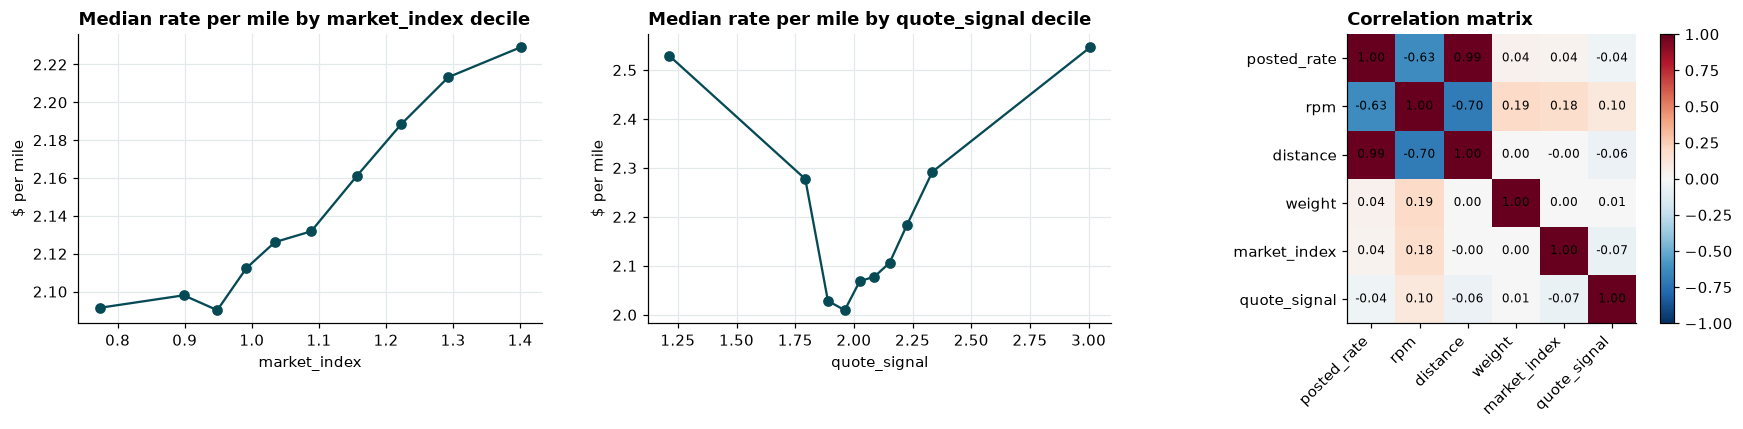

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes[:2], ["market_index", "quote_signal"]):
    b = pd.qcut(ok[col], 10, duplicates="drop")
    g = ok.groupby(b, observed=True)["rpm"].median()
    ax.plot([i.mid for i in g.index], g.values, marker="o", color="#064A56")
    ax.set_title(f"Median rate per mile by {col} decile")
    ax.set_xlabel(col)
    ax.set_ylabel("$ per mile")

corr_cols = ["posted_rate", "rpm", "distance", "weight", "market_index", "quote_signal"]
corr = ok[corr_cols].corr()
im = axes[2].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
axes[2].set_xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
axes[2].set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        axes[2].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
axes[2].set_title("Correlation matrix")
axes[2].grid(False)
fig.colorbar(im, ax=axes[2], fraction=0.046)
fig.tight_layout()
save(fig, "09_market_signals_and_correlation")
plt.show()

## 6. Validation strategy

**Time-based split:** train on January to August, test on September and October. Two
months of holdout mirror the two-month prediction horizon (November and December).
Early stopping uses the holdout, and the final model is then retrained on all January
to October data with the same number of trees (plus 10% for the extra data).

**Why not a random split?** Randomly mixing dates lets the model learn from loads on the
same days and market conditions it is tested on. The comparison below trains the same
model on a random 80/20 split. A lower error there would be an optimistic estimate that
the real November and December predictions cannot achieve.

In [33]:
train = add_features(train_clean[~train_clean["rate_outlier"]].drop(columns=["rpm", "rpm_ratio", "rate_outlier"]))
valid = add_features(valid_clean)

fit = train[train["date"] < HOLDOUT_START]
hold = train[train["date"] >= HOLDOUT_START]
print(f"Train (Jan-Aug): {len(fit):,} rows | Holdout (Sep-Oct): {len(hold):,} rows")

model = lgb.LGBMRegressor(**PARAMS)
model.fit(
    fit[FEATURES], np.log(fit["posted_rate"]),
    eval_set=[(fit[FEATURES], np.log(fit["posted_rate"])), (hold[FEATURES], np.log(hold["posted_rate"]))],
    eval_names=["train", "holdout"],
    callbacks=[lgb.early_stopping(200, verbose=False)],
)
best_iter = model.best_iteration_
hold = hold.assign(pred=np.exp(model.predict(hold[FEATURES], num_iteration=best_iter)))
print(f"Best iteration: {best_iter}")

# Same model on a random split, for comparison only
shuffled = train.sample(frac=1, random_state=0)
cut = int(len(shuffled) * 0.8)
r_fit, r_test = shuffled.iloc[:cut], shuffled.iloc[cut:]
random_model = lgb.LGBMRegressor(**{**PARAMS, "n_estimators": best_iter}).fit(r_fit[FEATURES], np.log(r_fit["posted_rate"]))
random_pred = np.exp(random_model.predict(r_test[FEATURES]))

pd.DataFrame({
    "Time-based split (Sep-Oct holdout)": metrics(hold["posted_rate"], hold["pred"]),
    "Random 80/20 split": metrics(r_test["posted_rate"], random_pred),
}).T

Train (Jan-Aug): 37,944 rows | Holdout (Sep-Oct): 9,379 rows
Best iteration: 157


,MAE,RMSE,MAPE_%
Time-based split (Sep-Oct holdout),81.97,117.87,3.18
Random 80/20 split,48.75,75.64,2.10


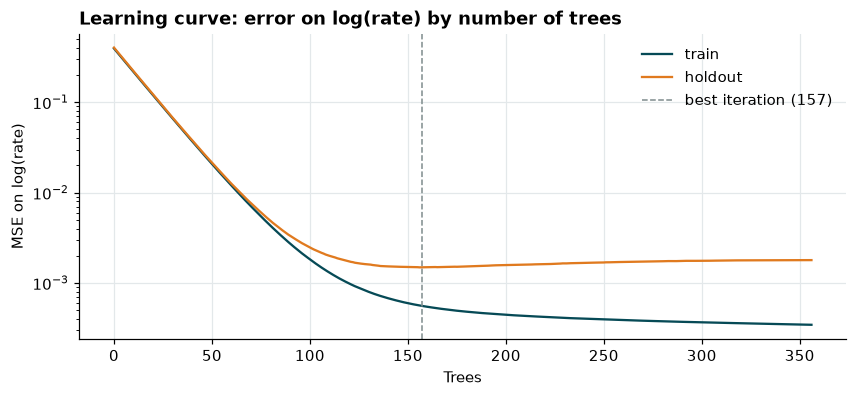

In [34]:
history = model.evals_result_
fig, ax = plt.subplots(figsize=(9, 3.6))
for name, color in [("train", "#064A56"), ("holdout", "#E07A1F")]:
    ax.plot(history[name]["l2"], color=color, label=name)
ax.axvline(best_iter, color="#7F8C8D", ls="--", lw=1, label=f"best iteration ({best_iter})")
ax.set_yscale("log")
ax.set_title("Learning curve: error on log(rate) by number of trees")
ax.set_xlabel("Trees")
ax.set_ylabel("MSE on log(rate)")
ax.legend(frameon=False)
save(fig, "10_learning_curve")
plt.show()

## 7. Model results

Two simple baselines show what the model adds:
- **Median rate per mile by equipment x distance**: the simplest pricing rule a broker might use
- **quote_signal x distance**: tests whether `quote_signal` on its own is a usable rate-per-mile quote

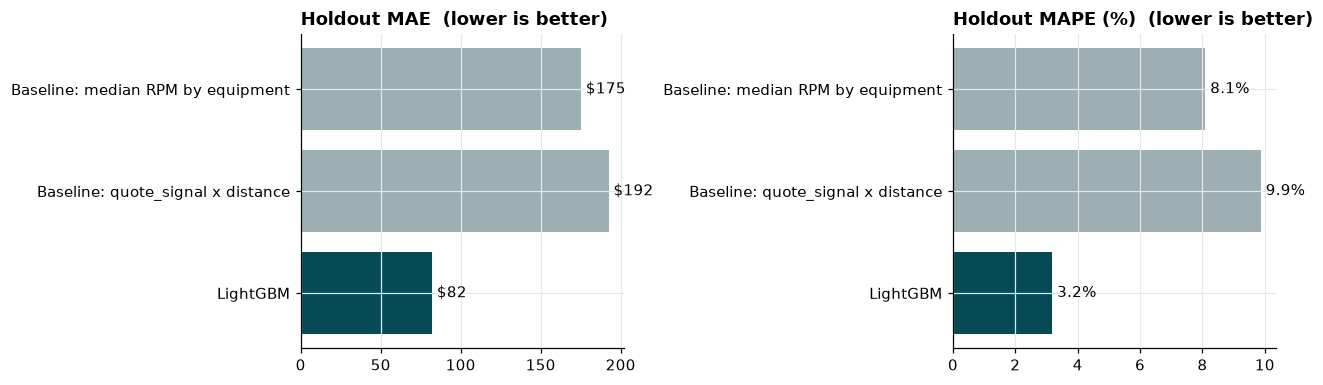

,MAE,RMSE,MAPE_%
Baseline: median RPM by equipment,175.09,258.15,8.09
Baseline: quote_signal x distance,192.37,344.31,9.87
LightGBM,81.97,117.87,3.18


In [35]:
eq_rpm = (fit["posted_rate"] / fit["distance"]).groupby(fit["equipment"].astype(str)).median()
hold = hold.assign(
    base_equipment=hold["equipment"].astype(str).map(eq_rpm) * hold["distance"],
    base_quote=hold["quote_signal"] * hold["distance"],
)

results = pd.DataFrame({
    "Baseline: median RPM by equipment": metrics(hold["posted_rate"], hold["base_equipment"]),
    "Baseline: quote_signal x distance": metrics(hold["posted_rate"], hold["base_quote"]),
    "LightGBM": metrics(hold["posted_rate"], hold["pred"]),
}).T

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
colors = ["#9DAFB3", "#9DAFB3", "#064A56"]
for ax, col, fmt in [(axes[0], "MAE", "${:,.0f}"), (axes[1], "MAPE_%", "{:.1f}%")]:
    bars = ax.barh(results.index, results[col], color=colors)
    ax.invert_yaxis()
    ax.set_title(f"Holdout {col.replace('_%', ' (%)')}  (lower is better)")
    for b, v in zip(bars, results[col]):
        ax.text(v, b.get_y() + b.get_height() / 2, " " + fmt.format(v), va="center")
fig.tight_layout()
save(fig, "11_model_vs_baselines")
plt.show()
results

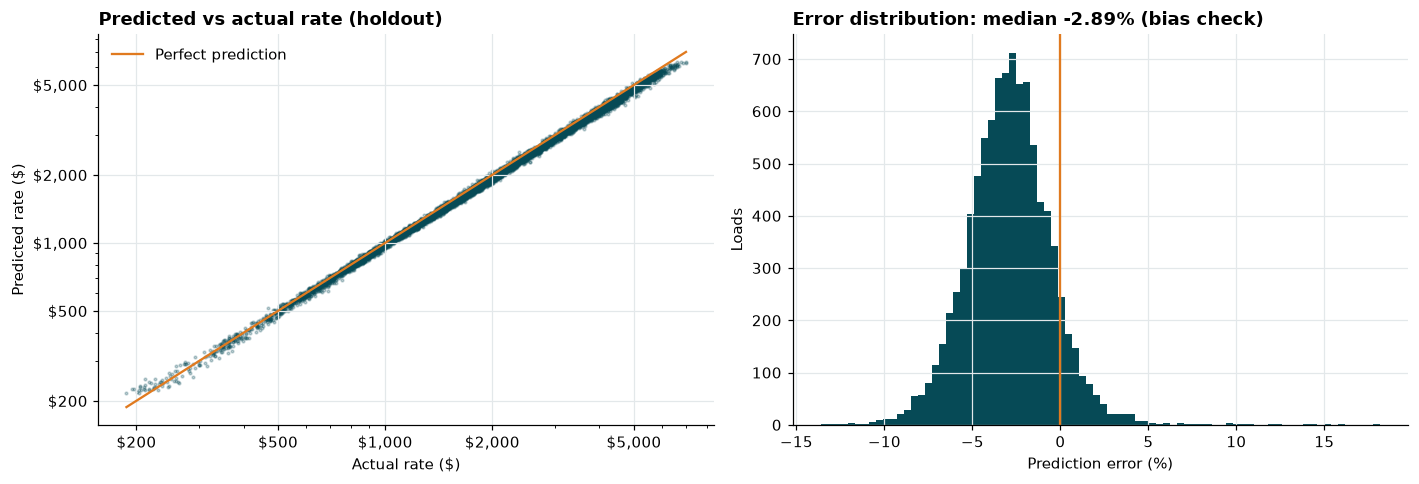

within 2%     31.2%
within 5%     82.5%
within 10%    99.6%
Name: share of holdout loads, dtype: object

In [36]:
hold = hold.assign(error_pct=(hold["pred"] - hold["posted_rate"]) / hold["posted_rate"] * 100)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(hold["posted_rate"], hold["pred"], s=3, alpha=0.25, color="#064A56")
lims = [hold[["posted_rate", "pred"]].min().min(), hold[["posted_rate", "pred"]].max().max()]
axes[0].plot(lims, lims, color="#E07A1F", lw=1.5, label="Perfect prediction")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
dollar_log_axis(axes[0].xaxis)
dollar_log_axis(axes[0].yaxis)
axes[0].set_title("Predicted vs actual rate (holdout)")
axes[0].set_xlabel("Actual rate ($)")
axes[0].set_ylabel("Predicted rate ($)")
axes[0].legend(frameon=False)

axes[1].hist(hold["error_pct"].clip(-30, 30), bins=80, color="#064A56")
axes[1].axvline(0, color="#E07A1F", lw=1.5)
axes[1].set_title(f"Error distribution: median {hold['error_pct'].median():+.2f}% (bias check)")
axes[1].set_xlabel("Prediction error (%)")
axes[1].set_ylabel("Loads")
fig.tight_layout()
save(fig, "12_predicted_vs_actual")
plt.show()

within = {f"within {k}%": f"{(hold['error_pct'].abs() <= k).mean():.1%}" for k in (2, 5, 10)}
pd.Series(within, name="share of holdout loads")

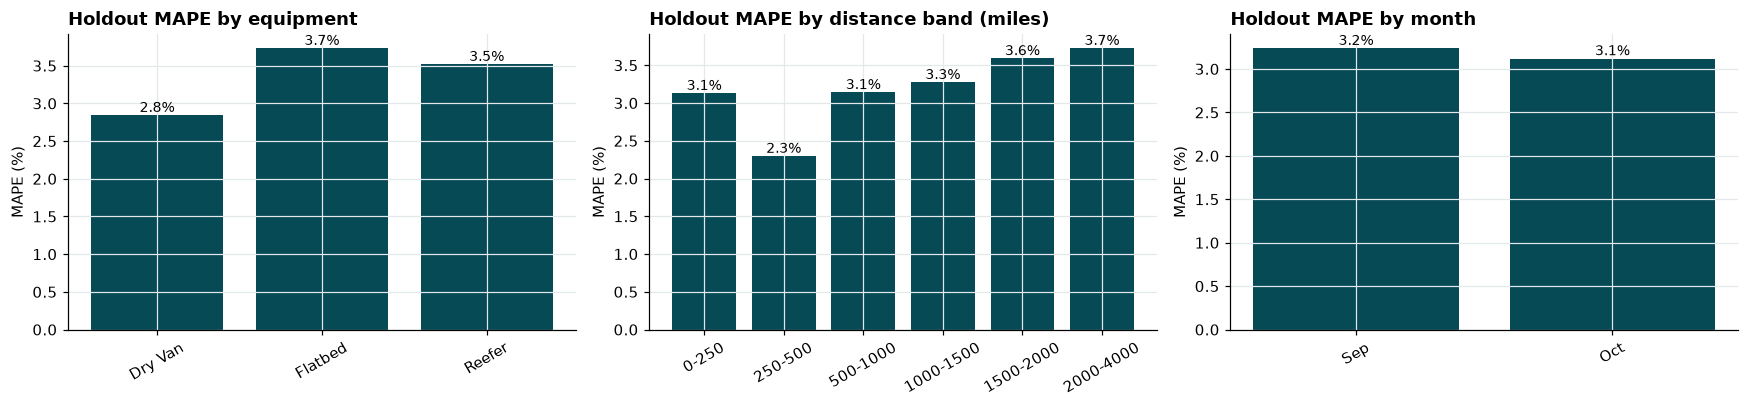

loads     MAE  MAPE %
equipment Dry Van    5275.0   65.24    2.84
          Flatbed    1746.0  103.01    3.73
          Reefer     2358.0  103.82    3.52
distance  0-250       544.0   13.98    3.13
          250-500    1511.0   21.86    2.30
          500-1000   2927.0   53.44    3.14
          1000-1500  1735.0   85.68    3.27
          1500-2000  1149.0  130.53    3.59
          2000-4000  1513.0  180.49    3.73
month     Sep        4606.0   86.30    3.24
          Oct        4773.0   77.79    3.12

In [37]:
def segment_errors(df, by):
    return df.groupby(by, observed=True).apply(
        lambda g: pd.Series({"loads": len(g), "MAE": np.mean(np.abs(g["pred"] - g["posted_rate"])),
                             "MAPE %": np.mean(np.abs(g["error_pct"]))}), include_groups=False)


seg_eq = segment_errors(hold, hold["equipment"].astype(str))
seg_dist = segment_errors(hold, pd.cut(hold["distance"], [0, 250, 500, 1000, 1500, 2000, 4000]))
seg_dist.index = [f"{int(i.left)}-{int(i.right)}" for i in seg_dist.index]
seg_month = segment_errors(hold, hold["date"].dt.month)
seg_month.index = pd.to_datetime(seg_month.index.astype(str), format="%m").strftime("%b")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, seg, title in [(axes[0], seg_eq, "equipment"), (axes[1], seg_dist, "distance band (miles)"),
                       (axes[2], seg_month, "month")]:
    ax.bar(seg.index, seg["MAPE %"], color="#064A56")
    ax.set_title(f"Holdout MAPE by {title}")
    ax.set_ylabel("MAPE (%)")
    ax.tick_params(axis="x", rotation=30)
    for i, v in enumerate(seg["MAPE %"]):
        ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
fig.tight_layout()
save(fig, "13_errors_by_segment")
plt.show()
pd.concat({"equipment": seg_eq, "distance": seg_dist, "month": seg_month}).round(2)

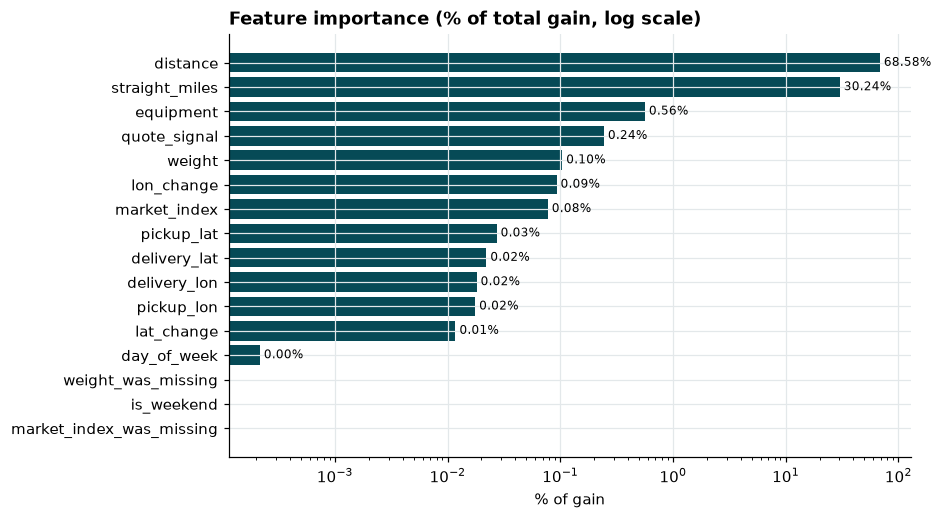

In [38]:
final = lgb.LGBMRegressor(**{**PARAMS, "n_estimators": int(best_iter * 1.1)})
final.fit(train[FEATURES], np.log(train["posted_rate"]))

importance = pd.Series(final.booster_.feature_importance("gain"), index=FEATURES)
importance = (importance / importance.sum() * 100).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance.index, importance.values, color="#064A56")
ax.set_xscale("log")
ax.set_title("Feature importance (% of total gain, log scale)")
ax.set_xlabel("% of gain")
for i, v in enumerate(importance.values):
    ax.text(v, i, f" {v:.2f}%", va="center", fontsize=8)
save(fig, "14_feature_importance")
plt.show()

## 8. Final prediction checks

The final model (trained on all January to October data) is applied to the 12,000
validation loads. These checks confirm the predictions are sensible: positive, on the
same scale as historical rates, consistent rate-per-mile by equipment, and no unusual
behaviour on loads involving cities the model has never seen.

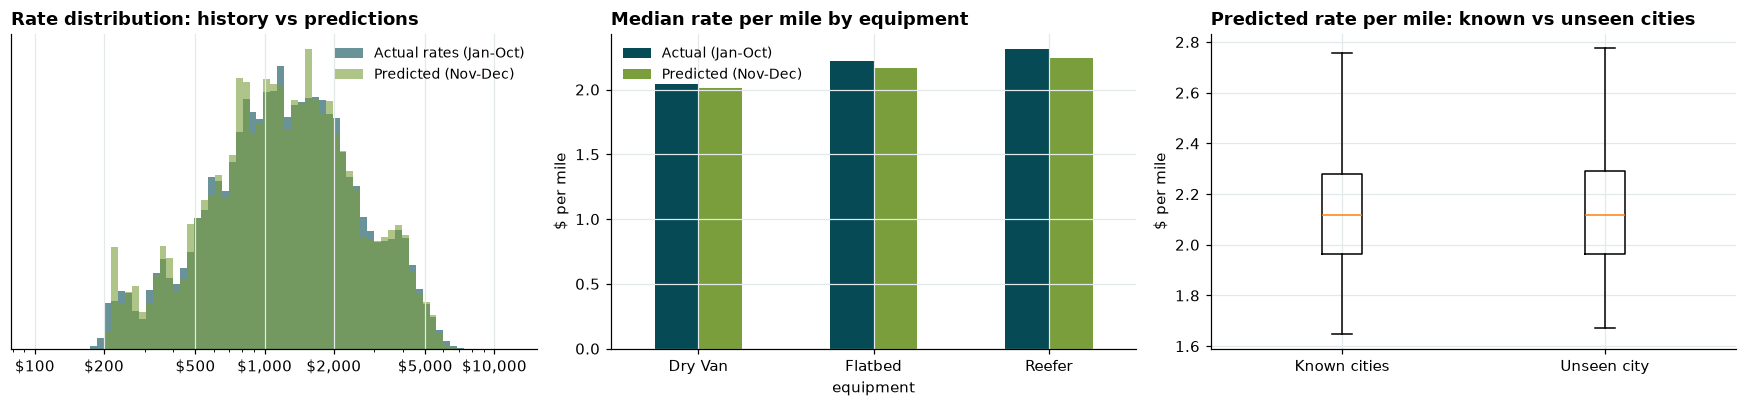

Predictions: 12,000 | all positive: True | missing: 0


,predicted_rate
count,12000.00
mean,2317.05
std,1333.81
min,211.62
25%,1253.96
50%,1998.69
75%,3307.64
max,6503.56


In [39]:
valid = valid.assign(pred=np.exp(final.predict(valid[FEATURES])))
valid["pred_rpm"] = valid["pred"] / valid["distance"]
valid["unseen_city"] = unseen_rows.values

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
b = np.logspace(np.log10(100), np.log10(12000), 70)
axes[0].hist(ok["posted_rate"], bins=b, density=True, alpha=0.6, color="#064A56", label="Actual rates (Jan-Oct)")
axes[0].hist(valid["pred"], bins=b, density=True, alpha=0.6, color="#7A9E3B", label="Predicted (Nov-Dec)")
axes[0].set_xscale("log")
dollar_log_axis(axes[0].xaxis)
axes[0].set_yticks([])
axes[0].set_title("Rate distribution: history vs predictions")
axes[0].legend(frameon=False, fontsize=9)

compare = pd.DataFrame({
    "Actual (Jan-Oct)": ok.groupby("equipment", observed=True)["rpm"].median(),
    "Predicted (Nov-Dec)": valid.groupby("equipment", observed=True)["pred_rpm"].median(),
}).reindex(EQUIPMENT)
compare.plot.bar(ax=axes[1], color=["#064A56", "#7A9E3B"], rot=0)
axes[1].set_title("Median rate per mile by equipment")
axes[1].set_ylabel("$ per mile")
axes[1].legend(frameon=False, fontsize=9)

axes[2].boxplot([valid.loc[~valid["unseen_city"], "pred_rpm"], valid.loc[valid["unseen_city"], "pred_rpm"]],
                showfliers=False)
axes[2].set_xticks([1, 2], ["Known cities", "Unseen city"])
axes[2].set_title("Predicted rate per mile: known vs unseen cities")
axes[2].set_ylabel("$ per mile")
fig.tight_layout()
save(fig, "15_final_prediction_checks")
plt.show()

print(f"Predictions: {len(valid):,} | all positive: {(valid['pred'] > 0).all()} | "
      f"missing: {int(valid['pred'].isna().sum())}")
valid["pred"].describe().round(2).to_frame("predicted_rate")

## 9. December chart: fixed inputs, only the date changes

The December inputs contain only the lane, distance, equipment, weight and date.
Coordinates are looked up from the city names. `market_index` and `quote_signal` are not
provided, so each day uses the median of real Dry Van loads in `validation.csv` on that
date. The chart compares the predictions with every historical Dry Van load on this lane.

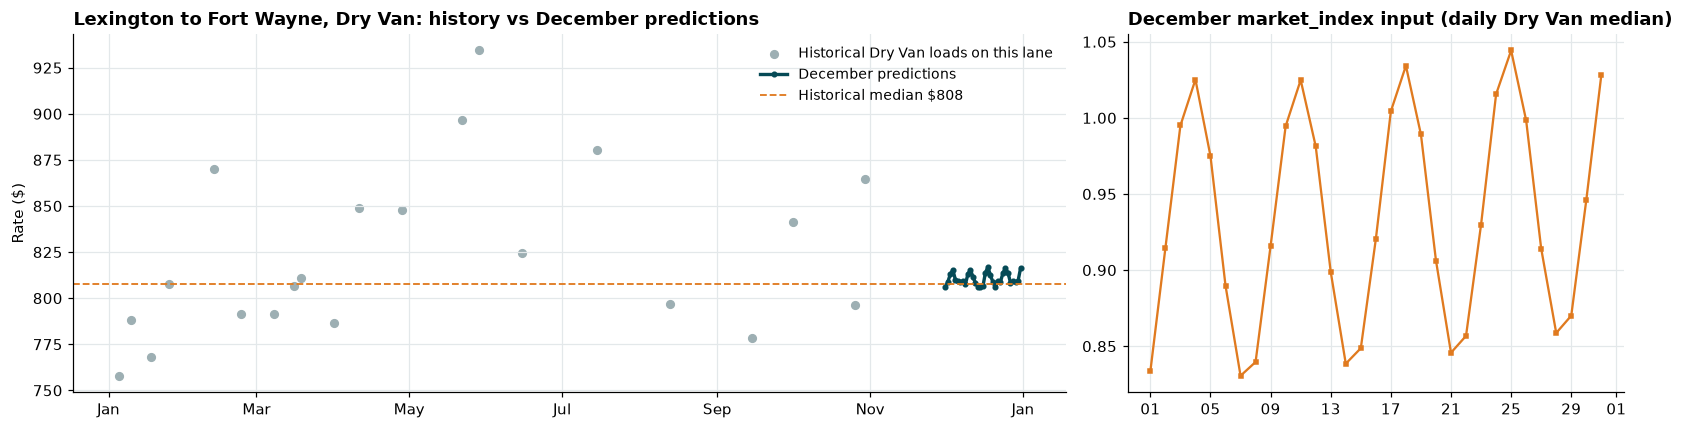

December predictions: $806 to $817
Historical Dry Van loads on this lane: 21 | median $808


In [40]:
dec_features = build_december(raw_dec, raw_train, raw_valid, valid_clean)
dec = raw_dec.copy()
dec["date"] = pd.to_datetime(dec["date"])
dec["predicted_rate"] = np.exp(final.predict(dec_features[FEATURES]))
dec["market_index"] = dec_features["market_index"].values

lane = ok[(ok["pickup"] == "Lexington") & (ok["delivery"] == "Fort Wayne") & (ok["equipment"] == "Dry Van")]

fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [2, 1]})
axes[0].scatter(lane["date"], lane["posted_rate"], color="#9DAFB3", s=25, label="Historical Dry Van loads on this lane")
axes[0].plot(dec["date"], dec["predicted_rate"], color="#064A56", lw=2.2, marker="o", ms=3, label="December predictions")
if len(lane):
    axes[0].axhline(lane["posted_rate"].median(), color="#E07A1F", ls="--", lw=1.2,
                    label=f"Historical median ${lane['posted_rate'].median():,.0f}")
axes[0].set_title("Lexington to Fort Wayne, Dry Van: history vs December predictions")
axes[0].set_ylabel("Rate ($)")
axes[0].legend(frameon=False, fontsize=9)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b"))

axes[1].plot(dec["date"], dec["market_index"], color="#E07A1F", marker="s", ms=3)
axes[1].set_title("December market_index input (daily Dry Van median)")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d"))
fig.tight_layout()
save(fig, "16_december_vs_lane_history")
plt.show()

print(f"December predictions: ${dec['predicted_rate'].min():,.0f} to ${dec['predicted_rate'].max():,.0f}")
print(f"Historical Dry Van loads on this lane: {len(lane)} | median ${lane['posted_rate'].median():,.0f}")

## 10. Summary

**Data**
- 48,000 labelled loads (Jan to Oct 2025) and 12,000 loads to predict (Nov to Dec 2025): a forecasting problem.
- 8 cities in the validation set never appear in training (1,447 loads, about 12%), so the model uses coordinates rather than city names.
- `market_index` is the only feature with a large population shift (PSI above 0.25): the prediction period looks like January and September-October rather than the May-June peak. The model has seen this range, so it is not extrapolating.
- Distance, weight, `quote_signal` and the equipment mix are stable between training and validation.

**Data quality** (rules learned on training data, applied to both sets)
- Negative weights were a sign error and were converted to absolute values.
- Missing weight and `market_index` were imputed, with flags so the model can tell.
- Distances far above the typical 1.18x straight-line ratio were investigated and kept: they are all short trips (routing detours and a 70-mile minimum), not errors.
- About 1.5% of training rates had an implausible rate per mile and were removed from training only.

**Validation and model**
- Time-based split: train Jan to Aug, holdout Sep to Oct, mirroring the two-month prediction horizon.
- LightGBM on log(rate) cut the error by more than half compared with both baselines, with stable error across both holdout months.
- A random 80/20 split gives a much lower error than the time-based split, which shows a random split would overstate how well the model forecasts unseen months.
- Distance dominates the importance ranking; equipment and market signals adjust the price by a few percent.

**Limitation**
- No November or December data exists for training, so holiday seasonality cannot be learned directly. The December chart therefore stays close to the lane's historical median, moving only with the daily market inputs.